In [17]:
import matplotlib.pyplot as plt
import numpy as np
import os
import math
import time
import torch
import torch.nn as nn

In [18]:
maps_file = "Maps_Mtot_Nbody_IllustrisTNG_LH_z=0.00.npy"
maps = np.load(maps_file, mmap_mode="r")
params_file = "params_LH_Nbody_IllustrisTNG.txt"
params = np.loadtxt(params_file, comments="#")

In [19]:
print(np.shape(maps))
# 15000 2d maps of size 256x256 pixels
# 15 projections of each simulation are stored consecutively
# want to split test and training by simulation so there aren't any maps of the same simulation in
# both training and test

print(np.shape(params))
# the params file has 1000 rows for each simulation,
# & 6 columns: Omega_m, sigma_8, A_SN1, A_AGN1, A_SN2, A_AGN2

(15000, 256, 256)
(1000, 6)


In [20]:
rng = np.random.default_rng(42)          # fixed seed so the split is reproducible
sims = rng.permutation(1000)
train_sims, val_sims, test_sims = sims[:800], sims[800:900], sims[900:]

def sim_to_map_indices(sim_ids, maps_per_sim=15):
    return (sim_ids[:, None] * maps_per_sim + np.arange(maps_per_sim)).ravel()

train_idx = sim_to_map_indices(train_sims)
val_idx   = sim_to_map_indices(val_sims)
test_idx  = sim_to_map_indices(test_sims)
labels = np.repeat(params[:, :2], 15, axis=0)   # per-map labels

In [21]:
print(len(train_idx), len(val_idx), len(test_idx))
# (maps[train_idx] would copy ~3 GB into RAM just to get its length, so use the index arrays)

12000 1500 1500


In [22]:
# make sure the 15 projections of each sim are not split among training, validation and test
sims_in = lambda idx: set(idx // 15)
assert sims_in(train_idx).isdisjoint(sims_in(val_idx))
assert sims_in(train_idx).isdisjoint(sims_in(test_idx))
assert sims_in(val_idx).isdisjoint(sims_in(test_idx))
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(maps)
print("split OK: every simulation is in exactly one of train / val / test")

split OK: every simulation is in exactly one of train / val / test


## The CNN

1. **Preprocess:** take log10 of each map and standardize it with training-set statistics. Rescale the labels (Omega_m, sigma_8) to [0, 1].
2. **Network:** 6 convolutional blocks, each halving the image (256 → 4 pixels), then global average pooling and a small fully connected head. The head outputs a **mean and an uncertainty** for each parameter.
3. **Loss:** Gaussian negative log-likelihood, so the network learns error bars along with its predictions.
4. **Augmentation:** random 90° rotations and flips, since cosmology has no preferred direction.
5. **Training:** AdamW with a one-cycle learning-rate schedule. The model with the best validation loss is saved, and the test set is used only once, at the end.

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

CHUNK = 250   # maps read from disk at a time, to keep memory use low

def log_chunks(m, idx):
    """Yield log10 of the maps m[idx] in chunks. The matter density spans several
    orders of magnitude, so the log is a much better input for the network than raw values."""
    for i in range(0, len(idx), CHUNK):
        yield np.log10(np.asarray(m[idx[i:i+CHUNK]], dtype=np.float32))

# Normalization statistics from TRAINING maps only (a random subset is plenty), so test data never leaks in
tot, tot2, n = 0.0, 0.0, 0
for c in log_chunks(maps, np.sort(rng.choice(train_idx, 1500, replace=False))):
    c = c.astype(np.float64)
    tot += c.sum(); tot2 += (c**2).sum(); n += c.size
LOG_MEAN = tot / n
LOG_STD = np.sqrt(tot2 / n - LOG_MEAN**2)
print(f"log10(map) mean {LOG_MEAN:.3f}, std {LOG_STD:.3f}")

def prepare(m, idx):
    """Standardized log maps as a float16 tensor of shape (N, 1, 256, 256).
    float16 halves the RAM (train set ~1.6 GB instead of 3.1 GB); batches are converted to float32 for training."""
    X = np.empty((len(idx), 1, 256, 256), dtype=np.float16)
    for i, c in zip(range(0, len(idx), CHUNK), log_chunks(m, idx)):
        assert np.isfinite(c).all(), "map has zero or negative pixels; log10 failed"
        X[i:i+len(c), 0] = (c - LOG_MEAN) / LOG_STD
    return torch.from_numpy(X)

# Labels: rescale Omega_m and sigma_8 to [0, 1] so both get equal weight in the loss
y_lo, y_hi = params[:, :2].min(0), params[:, :2].max(0)
y_span = y_hi - y_lo
norm_y   = lambda y: (y - y_lo) / y_span
denorm_y = lambda y: y * y_span + y_lo

X_train, X_val, X_test = prepare(maps, train_idx), prepare(maps, val_idx), prepare(maps, test_idx)
Y_train, Y_val, Y_test = [torch.tensor(norm_y(labels[i]), dtype=torch.float32)
                          for i in (train_idx, val_idx, test_idx)]
print(X_train.shape, Y_train.shape, X_val.shape, X_test.shape)

device: cpu
log10(map) mean 9.066, std 0.497
torch.Size([12000, 1, 256, 256]) torch.Size([12000, 2]) torch.Size([1500, 1, 256, 256]) torch.Size([1500, 1, 256, 256])


In [24]:
# shrink the maps to 128x128 to make it faster

import torch.nn.functional as F
def downsample(X, bs=500):
    return torch.cat([F.avg_pool2d(X[i:i+bs].float(), 2).half() for i in range(0, len(X), bs)])
X_train, X_val, X_test = downsample(X_train), downsample(X_val), downsample(X_test)

In [25]:
def conv_block(c_in, c_out):
    """Two 3x3 convolutions, then a stride-2 convolution that halves the image size.
    Circular padding because the simulation box is periodic: the maps wrap around at the edges."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, padding_mode="circular", bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
        nn.Conv2d(c_out, c_out, 3, padding=1, padding_mode="circular", bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
        nn.Conv2d(c_out, c_out, 2, stride=2, bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
    )

class CosmoCNN(nn.Module):
    """256x256 map -> (mean, log variance) for (Omega_m, sigma_8)."""
    def __init__(self, width=8, dropout=0.3):
        # smaller width = faster, changed from 16 to 8
        super().__init__()
        w = width
        chans = [1, w, 2*w, 4*w, 8*w, 16*w, 16*w]      # image size 256 -> 128 -> 64 -> 32 -> 16 -> 8 -> 4
        self.features = nn.Sequential(*[conv_block(a, b) for a, b in zip(chans[:-1], chans[1:])])
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(chans[-1], 128), nn.LeakyReLU(0.2),
            nn.Dropout(dropout), nn.Linear(128, 4),
        )

    def forward(self, x):
        out = self.head(self.features(x))
        return out[:, :2], out[:, 2:].clamp(-12, 4)    # mean, log variance

def gaussian_nll(mean, log_var, y):
    """Negative log-likelihood of y under N(mean, exp(log_var)). Training on this instead of MSE
    makes the network also learn an error bar for each prediction."""
    return (0.5 * log_var + 0.5 * (y - mean) ** 2 / log_var.exp()).mean()

def augment(x):
    """The universe has no preferred direction, so a rotated or mirrored map has the same
    Omega_m and sigma_8. Random rotations by 90 degrees and flips give 8x more distinct training maps."""
    x = torch.rot90(x, int(torch.randint(4, (1,))), dims=(2, 3))
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

# quick shape check
with torch.no_grad():
    m, lv = CosmoCNN()(torch.zeros(2, 1, 256, 256))
print(m.shape, lv.shape)

torch.Size([2, 2]) torch.Size([2, 2])


In [26]:
EPOCHS = 10      # each epoch = one pass over the 12000 training maps
BATCH  = 64
LR     = 1e-3
CKPT   = "cosmo_cnn_best.pt"

torch.manual_seed(0)
model = CosmoCNN().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} trainable parameters")

torch.set_num_threads(os.cpu_count())

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
steps_per_epoch = math.ceil(len(X_train) / BATCH)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)

@torch.no_grad()
def predict(X, bs=256):
    """Return (mean, sigma) in normalized label units for every map in X."""
    model.eval()
    means, sigmas = [], []
    for i in range(0, len(X), bs):
        m, log_var = model(X[i:i+bs].to(device).float())
        means.append(m.cpu()); sigmas.append((0.5 * log_var).exp().cpu())
    return torch.cat(means).numpy(), torch.cat(sigmas).numpy()

def nll_numpy(mean, sigma, y):
    return np.mean(np.log(sigma) + 0.5 * ((y - mean) / sigma) ** 2)

history = {"train": [], "val": []}
best_val = np.inf
for epoch in range(EPOCHS):
    model.train()
    t0, running = time.time(), 0.0
    order = torch.randperm(len(X_train))
    for i in range(0, len(X_train), BATCH):
        b = order[i:i+BATCH]
        x = augment(X_train[b].to(device, non_blocking=True).float())
        y = Y_train[b].to(device)
        mean, log_var = model(x)
        loss = gaussian_nll(mean, log_var, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step(); sched.step()
        running += loss.item() * len(b)

    vm, vs = predict(X_val)
    val_loss = nll_numpy(vm, vs, Y_val.numpy())
    val_rmse = np.sqrt(np.mean((denorm_y(vm) - denorm_y(Y_val.numpy())) ** 2, axis=0))
    history["train"].append(running / len(X_train)); history["val"].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), CKPT)
    print(f"epoch {epoch+1:2d} | train {history['train'][-1]:.3f} | val {val_loss:.3f} "
          f"| val RMSE  Om {val_rmse[0]:.4f}  s8 {val_rmse[1]:.4f} | {time.time()-t0:.0f}s"
          + ("  *saved" if val_loss == best_val else ""))

761,436 trainable parameters
epoch  1 | train -0.237 | val -0.636 | val RMSE  Om 0.0913  s8 0.1368 | 121s  *saved
epoch  2 | train -1.038 | val -0.884 | val RMSE  Om 0.0918  s8 0.0969 | 107s  *saved
epoch  3 | train -1.322 | val -1.192 | val RMSE  Om 0.0910  s8 0.0483 | 113s  *saved
epoch  4 | train -1.465 | val -1.139 | val RMSE  Om 0.0782  s8 0.0678 | 100s
epoch  5 | train -1.536 | val -1.793 | val RMSE  Om 0.0368  s8 0.0334 | 125s  *saved
epoch  6 | train -1.632 | val -1.833 | val RMSE  Om 0.0389  s8 0.0387 | 193s  *saved
epoch  7 | train -1.713 | val -1.873 | val RMSE  Om 0.0355  s8 0.0357 | 199s  *saved
epoch  8 | train -1.780 | val -1.969 | val RMSE  Om 0.0324  s8 0.0375 | 180s  *saved
epoch  9 | train -1.814 | val -2.051 | val RMSE  Om 0.0285  s8 0.0298 | 185s  *saved
epoch 10 | train -1.824 | val -2.046 | val RMSE  Om 0.0302  s8 0.0314 | 190s


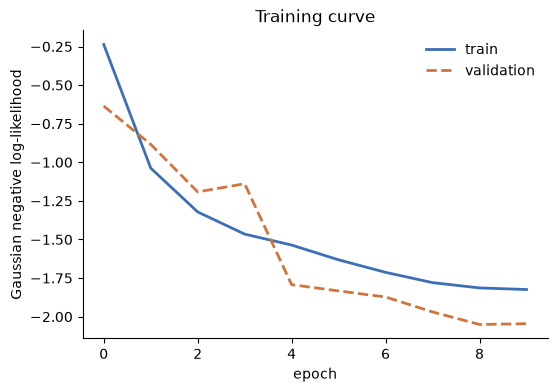

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history["train"], color="#3b6fb6", lw=2, label="train")
ax.plot(history["val"], color="#d0743c", lw=2, ls="--", label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("Gaussian negative log-likelihood")
ax.set_title("Training curve")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [28]:
# Evaluate the best model (lowest validation loss) on the held-out TEST simulations
model.load_state_dict(torch.load(CKPT, map_location=device))
pred_mean, pred_sig = predict(X_test)
pred_mean = denorm_y(pred_mean)          # back to physical units
pred_sig  = pred_sig * y_span
true      = labels[test_idx]

# Each sim has 15 maps of the same universe; average them to get one estimate per simulation
sim_mean = pred_mean.reshape(-1, 15, 2).mean(1)
sim_sig  = pred_sig.reshape(-1, 15, 2).mean(1)    # typical single-map uncertainty
sim_true = true.reshape(-1, 15, 2)[:, 0]

names = ["Omega_m", "sigma_8"]
for j, name in enumerate(names):
    err = pred_mean[:, j] - true[:, j]
    rmse = np.sqrt(np.mean(err**2))
    r2 = 1 - np.sum(err**2) / np.sum((true[:, j] - true[:, j].mean())**2)
    rel = np.mean(np.abs(err) / true[:, j])
    within = np.mean(np.abs(err) < pred_sig[:, j])     # should be ~0.68 if sigma is calibrated
    rmse_sim = np.sqrt(np.mean((sim_mean[:, j] - sim_true[:, j])**2))
    print(f"{name}: RMSE {rmse:.4f} | mean rel. error {100*rel:.1f}% | R^2 {r2:.3f} "
          f"| truth within 1 sigma: {100*within:.0f}% | RMSE of 15-map average {rmse_sim:.4f}")

Omega_m: RMSE 0.0296 | mean rel. error 7.8% | R^2 0.935 | truth within 1 sigma: 88% | RMSE of 15-map average 0.0188
sigma_8: RMSE 0.0302 | mean rel. error 2.8% | R^2 0.936 | truth within 1 sigma: 88% | RMSE of 15-map average 0.0189


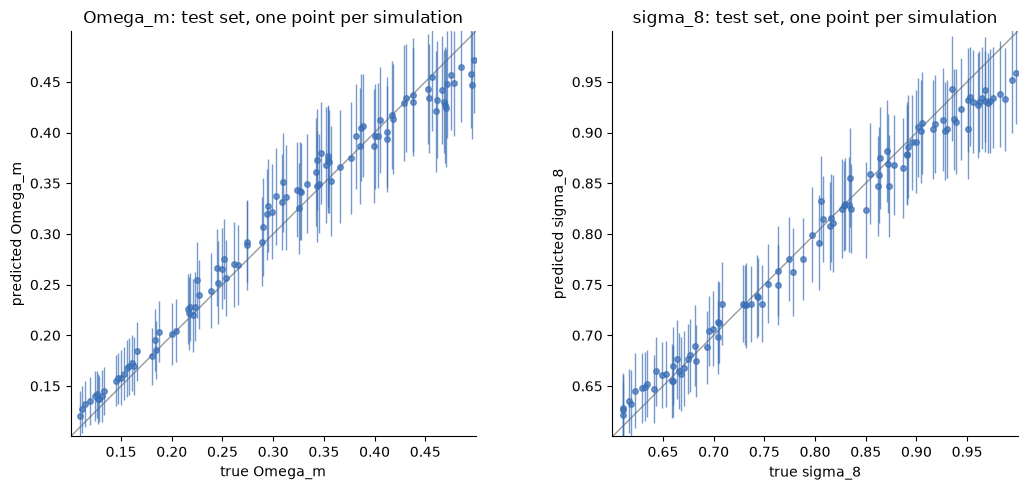

In [29]:
# Predicted vs. true, one point per simulation (average of its 15 maps), with the predicted 1-sigma error
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for j, (ax, name) in enumerate(zip(axes, names)):
    lo, hi = y_lo[j], y_hi[j]
    ax.plot([lo, hi], [lo, hi], color="0.6", lw=1, zorder=0)          # perfect prediction
    ax.errorbar(sim_true[:, j], sim_mean[:, j], yerr=sim_sig[:, j], fmt="o", ms=4,
                color="#3b6fb6", ecolor="#3b6fb6", elinewidth=1, alpha=0.7, capsize=0)
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel(f"predicted {name}")
    ax.set_title(f"{name}: test set, one point per simulation")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [30]:
# Extra check: the CV set. All 27 CV simulations share ONE cosmology (Omega_m=0.3, sigma_8=0.8)
# and differ only in their random initial conditions. The scatter of the predictions shows how much
# cosmic variance alone moves the estimate, and the mean shows whether the network is biased.
maps_cv   = np.load("Maps_Mtot_Nbody_IllustrisTNG_CV_z=0.00.npy", mmap_mode="r")
params_cv = np.loadtxt("params_CV_Nbody_IllustrisTNG.txt", comments="#")
X_cv = downsample(prepare(maps_cv, np.arange(len(maps_cv))))   # same 128x128 preprocessing as training!
cv_mean, cv_sig = predict(X_cv)
cv_mean, cv_sig = denorm_y(cv_mean), cv_sig * y_span

for j, name in enumerate(names):
    print(f"{name}: truth {params_cv[0, j]:.3f} | mean prediction {cv_mean[:, j].mean():.4f} "
          f"| scatter between maps {cv_mean[:, j].std():.4f} | mean predicted sigma {cv_sig[:, j].mean():.4f}")

Omega_m: truth 0.300 | mean prediction 0.3160 | scatter between maps 0.0305 | mean predicted sigma 0.0433
sigma_8: truth 0.800 | mean prediction 0.8006 | scatter between maps 0.0300 | mean predicted sigma 0.0436


## Power-spectrum baseline

Does the CNN learn anything beyond the power spectrum P(k)? Compute the 2D P(k) of each map, train a small fully connected network on log P(k) to predict (Omega_m, sigma_8), and compare its test error with the CNN's. It uses the same split, the same loss, and the same k-range the CNN sees (up to the Nyquist frequency of the 128×128 maps).

P(k) captures all the information in a Gaussian field. The late-time matter field has halos, filaments and voids and is strongly non-Gaussian, so any advantage the CNN has measures the information P(k) misses.

25 k-bins from 0.27 to 14.8 h/Mpc
correlation of log10(mean map density) with Omega_m: 0.7459


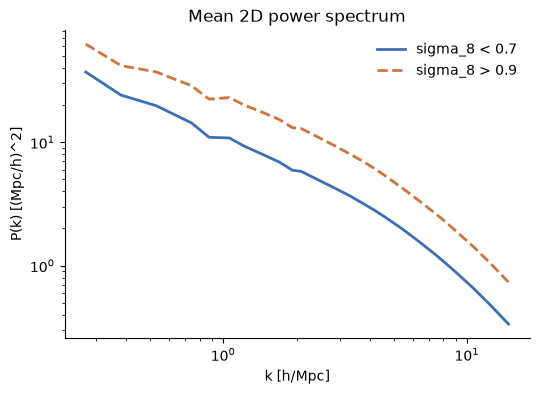

In [31]:
# ---- 2D matter power spectrum of every map ----
BOX   = 25.0                       # CAMELS box size in Mpc/h (the maps are 256 px across)
k_f   = 2 * np.pi / BOX            # fundamental mode, ~0.25 h/Mpc
K_NYQ = np.pi * 128 / BOX          # Nyquist frequency of the 128x128 maps the CNN sees, ~16 h/Mpc
CUTOFFS = [1.0, 2.0, 4.0, 8.0, K_NYQ]   # k_max values (h/Mpc) for the scale-cutoff test

# |k| of every pixel in Fourier space, and log-spaced bins from k_f to K_NYQ (cutoffs are bin edges)
n = np.fft.fftfreq(256) * 256
kmag = np.sqrt(n[:, None]**2 + n[None, :]**2).ravel() * k_f
edges = np.unique(np.concatenate([np.geomspace(0.999 * k_f, K_NYQ, 26), CUTOFFS]))
bin_of = np.digitize(kmag, edges) - 1               # k=0 and k>K_NYQ fall outside the bins
inside = (bin_of >= 0) & (bin_of < len(edges) - 1)
onehot = np.zeros((kmag.size, len(edges) - 1))
onehot[np.where(inside)[0], bin_of[inside]] = 1
counts = onehot.sum(0)
keep = counts > 0                                   # the lowest-k log bins can contain no modes
W = onehot[:, keep] / counts[keep]                  # averaging matrix: pixel |delta_k|^2 -> bin average
k_hi = edges[1:][keep]                              # upper edge of each kept bin
k_mid = np.sqrt(edges[:-1] * edges[1:])[keep]

PK_FILE = "pk_features.npz"                         # cached: reading all 15000 maps takes a minute or two
cached = os.path.exists(PK_FILE) and np.array_equal(np.load(PK_FILE)["edges"], edges)
if cached:
    d = np.load(PK_FILE); log_pk, log_mean = d["log_pk"], d["log_mean"]
else:
    t0 = time.time()
    log_pk, log_mean = np.empty((len(maps), keep.sum())), np.empty(len(maps))
    for i in range(0, len(maps), CHUNK):
        c = np.asarray(maps[i:i+CHUNK], dtype=np.float64)
        mean = c.mean(axis=(1, 2))
        delta = c / mean[:, None, None] - 1                       # overdensity field
        P = np.abs(np.fft.fft2(delta)) ** 2 * BOX**2 / 256**4      # P(k) in (Mpc/h)^2
        log_pk[i:i+len(c)] = np.log10(P.reshape(len(c), -1) @ W)
        log_mean[i:i+len(c)] = np.log10(mean)
    np.savez(PK_FILE, log_pk=log_pk, log_mean=log_mean, edges=edges)
    print(f"computed P(k) for {len(maps)} maps in {time.time()-t0:.0f}s")
print(f"{keep.sum()} k-bins from {k_mid[0]:.2f} to {k_mid[-1]:.1f} h/Mpc")

# The mean density of a total-matter map is proportional to Omega_m (mean density = Omega_m * rho_crit * depth),
# so a map hands Omega_m over almost for free. P(k) of the overdensity throws that away, so we test both.
print(f"correlation of log10(mean map density) with Omega_m: {np.corrcoef(log_mean, labels[:, 0])[0, 1]:.4f}")

# Sanity check: P(k) should rise with sigma_8 (amplitude of fluctuations)
lo8, hi8 = labels[:, 1] < 0.7, labels[:, 1] > 0.9
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(k_mid, 10 ** log_pk[lo8].mean(0), color="#3b6fb6", lw=2, label="sigma_8 < 0.7")
ax.loglog(k_mid, 10 ** log_pk[hi8].mean(0), color="#d0743c", lw=2, ls="--", label="sigma_8 > 0.9")
ax.set_xlabel("k [h/Mpc]"); ax.set_ylabel("P(k) [(Mpc/h)^2]"); ax.set_title("Mean 2D power spectrum")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [32]:
import copy

def train_mlp(F_tr, F_va, epochs=150, seed=0):
    """Small fully connected network on summary statistics, trained with the same Gaussian-NLL loss
    as the CNN so the two are directly comparable. Returns a function F -> (mean, sigma), normalized units."""
    torch.manual_seed(seed)
    mu, sd = F_tr.mean(0), F_tr.std(0) + 1e-12          # standardize features with TRAINING stats
    to_t = lambda F: torch.tensor((F - mu) / sd, dtype=torch.float32)
    Xtr, Xva = to_t(F_tr), to_t(F_va)
    net = nn.Sequential(nn.Linear(Xtr.shape[1], 128), nn.LeakyReLU(0.2),
                        nn.Linear(128, 128), nn.LeakyReLU(0.2), nn.Linear(128, 4))
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    split = lambda out: (out[:, :2], out[:, 2:].clamp(-12, 4))
    best, best_state = np.inf, None
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), 256):
            b = perm[i:i+256]
            loss = gaussian_nll(*split(net(Xtr[b])), Y_train[b])
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            vl = gaussian_nll(*split(net(Xva)), Y_val).item()
        if vl < best:                                    # keep the best-validation weights
            best, best_state = vl, copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state)

    @torch.no_grad()
    def predict_fn(F):
        m, lv = split(net(to_t(F)))
        return m.numpy(), (0.5 * lv).exp().numpy()
    return predict_fn

def test_metrics(mean_n, sig_n):
    """RMSE and 1-sigma coverage on the test set, in physical units, for (Omega_m, sigma_8)."""
    mean, sig, t = denorm_y(mean_n), sig_n * y_span, labels[test_idx]
    return np.sqrt(np.mean((mean - t) ** 2, axis=0)), np.mean(np.abs(mean - t) < sig, axis=0)

def pk_features(idx, kmax, with_mean):
    F = log_pk[idx][:, k_hi <= kmax * (1 + 1e-9)]       # only bins entirely below k_max
    return np.column_stack([F, log_mean[idx]]) if with_mean else F

# Train the P(k) models at every cutoff (cheap: each takes well under a minute)
results = {}
for label, with_mean in [("P(k) only", False), ("P(k) + mean density", True)]:
    results[label] = {}
    for kmax in CUTOFFS:
        f = train_mlp(pk_features(train_idx, kmax, with_mean), pk_features(val_idx, kmax, with_mean))
        results[label][kmax] = test_metrics(*f(pk_features(test_idx, kmax, with_mean)))
    print("done:", label)

# Compare with the CNN at full resolution
rmse_cnn = np.sqrt(np.mean((pred_mean - true) ** 2, axis=0))
cover_cnn = np.mean(np.abs(pred_mean - true) < pred_sig, axis=0)
print(f"\n{'test set, all scales':22s} | {'RMSE Om':>8s} {'RMSE s8':>8s} | {'1σ cover Om':>11s} {'s8':>4s}")
rows = [("CNN", rmse_cnn, cover_cnn)] + [(l, *results[l][K_NYQ]) for l in results]
for label, rmse, cover in rows:
    print(f"{label:22s} | {rmse[0]:8.4f} {rmse[1]:8.4f} | {100*cover[0]:10.0f}% {100*cover[1]:3.0f}%")

done: P(k) only
done: P(k) + mean density

test set, all scales   |  RMSE Om  RMSE s8 | 1σ cover Om   s8
CNN                    |   0.0296   0.0302 |         88%  88%
P(k) only              |   0.1033   0.0918 |         61%  63%
P(k) + mean density    |   0.0616   0.0853 |         65%  65%


## Scale-cutoff test: which scales carry the information?

Remove all Fourier modes with k > k_max from the maps (a sharp low-pass filter), **retrain** the CNN on the filtered maps, and see how much the error grows. Do the same for the power spectrum by keeping only the bins with k < k_max (that part already ran above).

The CNN has to be retrained for each cutoff. If you simply fed smoothed maps to the network trained on full-resolution maps, it would fail because the maps look different from anything it trained on. That would measure the mismatch, not the information content.

For scale: k_max = 1 h/Mpc keeps structures larger than about 6 Mpc/h (the size of big filaments and voids). k_max = 16 h/Mpc keeps everything down to about 0.4 Mpc/h (the size of individual halos).

Caveat: the CNN is filtered in log-density, while P(k) is computed from the linear overdensity. "k < k_max" therefore doesn't mean exactly the same thing for both, but it's close enough to see where the information lives.

**What to look for:**
- At large k_max, if the CNN is much better than P(k), the extra (non-Gaussian) information is on small scales.
- At small k_max, the CNN and P(k) should get closer together, because large scales are closer to Gaussian and P(k) captures most of their information.

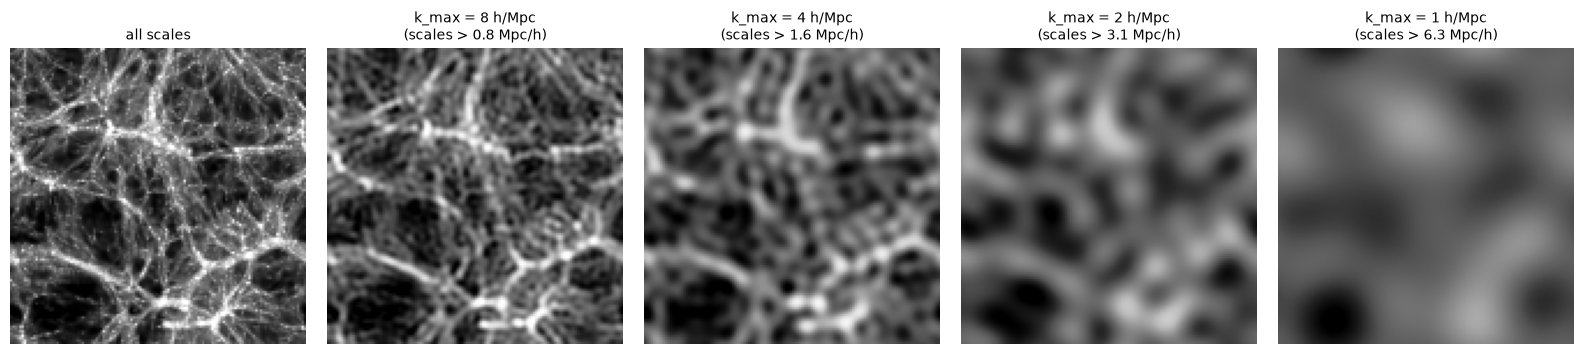

In [ ]:
def lowpass(X, kmax, bs=500):
    """Remove every Fourier mode with |k| > kmax (h/Mpc) from a stack of maps (N, 1, npix, npix)."""
    npix = X.shape[-1]
    n = torch.fft.fftfreq(npix) * npix
    kgrid = torch.sqrt(n[:, None]**2 + n[None, :]**2) * k_f
    mask = (kgrid <= kmax).float()
    out = torch.empty_like(X)
    for i in range(0, len(X), bs):
        x = X[i:i+bs].float()
        out[i:i+bs] = torch.fft.ifft2(torch.fft.fft2(x) * mask).real.to(X.dtype)
    return out

# Look at one test map with progressively more small-scale structure removed
example = X_test[:1]
shows = [K_NYQ, 8.0, 4.0, 2.0, 1.0]
fig, axes = plt.subplots(1, len(shows), figsize=(3.2 * len(shows), 3.4))
vmin, vmax = np.percentile(example.float().numpy(), [1, 99.5])
for ax, kmax in zip(axes, shows):
    img = example if kmax == K_NYQ else lowpass(example, kmax)
    ax.imshow(img[0, 0].float().numpy(), cmap="Greys_r", vmin=vmin, vmax=vmax)
    ax.set_title("all scales" if kmax == K_NYQ else f"k_max = {kmax:g} h/Mpc\n(scales > {2*np.pi/kmax:.1f} Mpc/h)",
                 fontsize=10)
    ax.axis("off")
plt.tight_layout()
#plt.savefig('scales.png')
plt.show()

In [34]:
def predict_net(net, X, bs=256):
    """Same as predict(), but for any network (not just the global `model`)."""
    net.eval()
    means, sigmas = [], []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            m, log_var = net(X[i:i+bs].to(device).float())
            means.append(m.cpu()); sigmas.append((0.5 * log_var).exp().cpu())
    return torch.cat(means).numpy(), torch.cat(sigmas).numpy()

def train_cnn(Xtr, Xva, ckpt, epochs=EPOCHS, seed=0):
    """Train a fresh CosmoCNN with the same settings as the main model. The best-validation
    weights are written to `ckpt` when training finishes. If `ckpt` already exists it is loaded
    instead of retraining (delete the file if you change the settings)."""
    torch.manual_seed(seed)
    net = CosmoCNN().to(device)
    if os.path.exists(ckpt):
        net.load_state_dict(torch.load(ckpt, map_location=device))
        print(f"  loaded {ckpt} (delete it to retrain)")
        return net
    opt = torch.optim.AdamW(net.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=epochs * math.ceil(len(Xtr) / BATCH))
    best, best_state = np.inf, None
    for epoch in range(epochs):
        net.train()
        t0 = time.time()
        order = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), BATCH):
            b = order[i:i+BATCH]
            mean, log_var = net(augment(Xtr[b].to(device).float()))
            loss = gaussian_nll(mean, log_var, Y_train[b].to(device))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        vm, vs = predict_net(net, Xva)
        vl = nll_numpy(vm, vs, Y_val.numpy())
        if vl < best:
            best, best_state = vl, copy.deepcopy(net.state_dict())
        print(f"  epoch {epoch+1:2d} | val {vl:.3f} | {time.time()-t0:.0f}s")
    net.load_state_dict(best_state)
    torch.save(best_state, ckpt)
    return net

# The full-resolution CNN is the model you already trained
rmse_cnn = np.sqrt(np.mean((pred_mean - true) ** 2, axis=0))
cover_cnn = np.mean(np.abs(pred_mean - true) < pred_sig, axis=0)
results["CNN"] = {K_NYQ: (rmse_cnn, cover_cnn)}

# Each cutoff is a full retraining: ~25 min each on your CPU at 10 epochs. Add 1.0 if you have time.
CNN_CUTS = [2.0, 4.0, 8.0]
for kmax in CNN_CUTS:
    print(f"CNN with k_max = {kmax:g} h/Mpc")
    net = train_cnn(lowpass(X_train, kmax), lowpass(X_val, kmax), f"cosmo_cnn_kmax{kmax:g}.pt")
    results["CNN"][kmax] = test_metrics(*predict_net(net, lowpass(X_test, kmax)))
    print(f"  test RMSE  Om {results['CNN'][kmax][0][0]:.4f}  s8 {results['CNN'][kmax][0][1]:.4f}")

CNN with k_max = 2 h/Mpc
  epoch  1 | val -0.589 | 156s
  epoch  2 | val -0.702 | 105s
  epoch  3 | val -0.729 | 192s
  epoch  4 | val -1.178 | 157s
  epoch  5 | val -0.392 | 105s
  epoch  6 | val -1.329 | 101s
  epoch  7 | val -1.312 | 104s
  epoch  8 | val -1.338 | 100s
  epoch  9 | val -1.350 | 108s
  epoch 10 | val -1.341 | 102s
  test RMSE  Om 0.0582  s8 0.0691
CNN with k_max = 4 h/Mpc
  epoch  1 | val -0.874 | 95s
  epoch  2 | val -1.229 | 105s
  epoch  3 | val -1.146 | 100s
  epoch  4 | val -1.350 | 97s
  epoch  5 | val -1.208 | 100s
  epoch  6 | val -1.360 | 99s
  epoch  7 | val -1.420 | 96s
  epoch  8 | val -1.545 | 105s
  epoch  9 | val -1.575 | 96s
  epoch 10 | val -1.568 | 97s
  test RMSE  Om 0.0471  s8 0.0551
CNN with k_max = 8 h/Mpc
  epoch  1 | val -0.879 | 105s
  epoch  2 | val -0.750 | 100s
  epoch  3 | val -1.158 | 95s
  epoch  4 | val -1.199 | 101s
  epoch  5 | val -1.283 | 102s
  epoch  6 | val -1.496 | 115s
  epoch  7 | val -1.734 | 97s
  epoch  8 | val -1.735 | 97

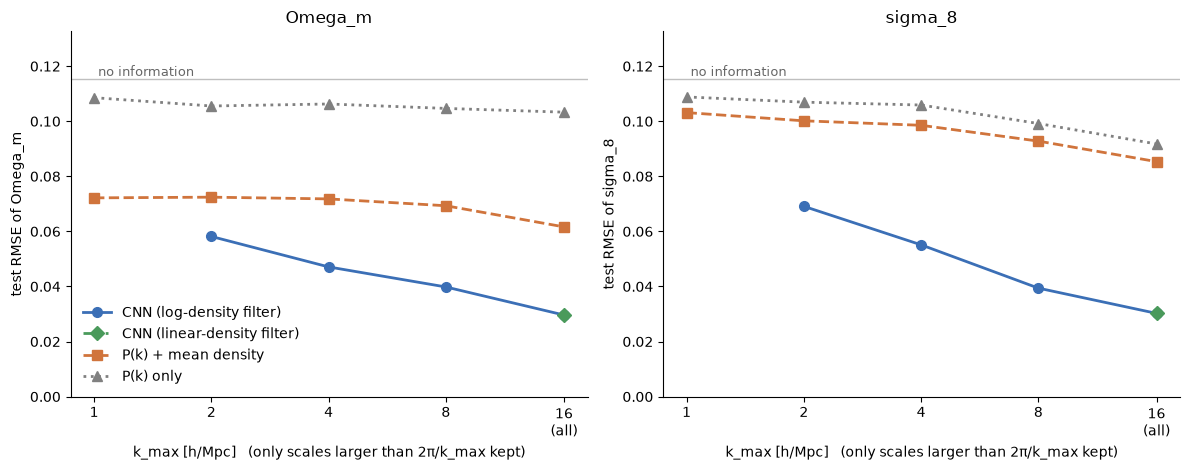

In [45]:
# Test RMSE vs. k_max: how the information depends on scale, for the CNN and the power spectrum
STYLES = {"CNN":                 dict(label="CNN (log-density filter)", color="#3b6fb6", marker="o", ls="-"),
          "CNN (linear filter)": dict(label="CNN (linear-density filter)", color="#4a9a5b", marker="D", ls="-."),
          "P(k) + mean density": dict(label="P(k) + mean density", color="#d0743c", marker="s", ls="--"),
          "P(k) only":           dict(label="P(k) only", color="0.5", marker="^", ls=":")}

def plot_cutoffs(save_as=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for j, (ax, name) in enumerate(zip(axes, names)):
        for key, st in STYLES.items():
            if key not in results:          # e.g. the linear-filter CNN before it has been trained
                continue
            ks = sorted(results[key])
            ax.plot(ks, [results[key][k][0][j] for k in ks], lw=2, ms=7, **st)
        # reference: RMSE of always guessing the middle of the (uniform) prior range = no information at all
        no_info = y_span[j] / np.sqrt(12)
        ax.axhline(no_info, color="0.75", lw=1, zorder=0)
        ax.text(CUTOFFS[0], no_info, " no information", va="bottom", color="0.4", fontsize=9)
        ax.set_xscale("log")
        ax.set_xticks(CUTOFFS)
        ax.set_xticklabels([f"{k:g}" for k in CUTOFFS[:-1]] + [f"{CUTOFFS[-1]:.0f}\n(all)"])
        ax.minorticks_off()
        ax.set_ylim(0, no_info * 1.15)
        ax.set_xlabel("k_max [h/Mpc]   (only scales larger than 2π/k_max kept)")
        ax.set_ylabel(f"test RMSE of {name}")
        ax.set_title(name)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[0].legend(frameon=False)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as)
    plt.show()

plot_cutoffs("scale_comparison.png")

## Sanity check: is the P(k) baseline as good as it can be?

"P(k) only" barely beats guessing. Before concluding that P(k) contains little information, check that the small MLP isn't simply failing to extract it. Fit the same features with different regressors:

- **The same MLP trained longer:** 500 epochs instead of 150.
- **Linear ridge regression:** a simple, robust fit that can't get stuck in a bad training run.
- **Quadratic ridge regression:** adds all pairwise products of the features, so the fit can curve.

**Reading the result:**
- If all methods land at about the same RMSE, that's how much information P(k) really carries, and the CNN comparison is fair.
- If one method does clearly better, the MLP baseline was too weak. Use the best method's numbers when comparing with the CNN.

In [ ]:
# this comparison makes sure the MLP (multilayer perceptron, a small fully connected network) wasn't just poorly trained.
# since it has slightly less or same error as the linear and quadratic regression, this increases confidence that it is
# fitting the data, but hitting limitations because of lack of information (P(k) alone doesn't have enough info)


def ridge_predict(F_tr, F_va, F_te, quadratic=False, lambdas=10.0 ** np.arange(-4, 5)):
    """Ridge (L2-regularized linear) regression of the normalized labels on the features.
    quadratic=True adds all pairwise products of the features, which allows some curvature.
    The regularization strength is picked on the validation set. Returns test predictions (normalized units)."""
    mu, sd = F_tr.mean(0), F_tr.std(0) + 1e-12
    def design(F):
        Z = (F - mu) / sd
        if quadratic:
            i, j = np.triu_indices(Z.shape[1])
            Z = np.column_stack([Z, Z[:, i] * Z[:, j]])
        return np.column_stack([np.ones(len(Z)), Z])
    Ztr, Zva, Zte = design(F_tr), design(F_va), design(F_te)
    ytr, yva = Y_train.numpy().astype(np.float64), Y_val.numpy().astype(np.float64)
    best = None
    for lam in lambdas:
        A = Ztr.T @ Ztr + lam * np.eye(Ztr.shape[1])
        A[0, 0] -= lam                                   # don't penalize the intercept
        w = np.linalg.solve(A, Ztr.T @ ytr)
        val_mse = np.mean((Zva @ w - yva) ** 2)
        if best is None or val_mse < best[0]:
            best = (val_mse, w)
    return Zte @ best[1]

def test_rmse(mean_n):
    return np.sqrt(np.mean((denorm_y(mean_n) - labels[test_idx]) ** 2, axis=0))

# Compare several regressors on the SAME features, at every cutoff
print(f"{'k_max':>6s} | {'features':20s} | {'MLP (150 ep)':>14s} | {'MLP (500 ep)':>14s} | {'linear ridge':>14s} | {'quadratic ridge':>15s}")
print(f"{'':>6s} | {'':20s} | {'Om':>6s} {'s8':>7s} | {'Om':>6s} {'s8':>7s} | {'Om':>6s} {'s8':>7s} | {'Om':>6s} {'s8':>8s}")
for with_mean, flabel in [(False, "P(k) only"), (True, "P(k) + mean density")]:
    for kmax in CUTOFFS:
        Ftr, Fva, Fte = (pk_features(i, kmax, with_mean) for i in (train_idx, val_idx, test_idx))
        mlp150 = results[flabel][kmax][0]                                   # already trained above
        mlp500 = test_rmse(train_mlp(Ftr, Fva, epochs=500)(Fte)[0]) if kmax == K_NYQ else None
        lin = test_rmse(ridge_predict(Ftr, Fva, Fte))
        quad = test_rmse(ridge_predict(Ftr, Fva, Fte, quadratic=True))
        m500 = f"{mlp500[0]:6.4f} {mlp500[1]:7.4f}" if mlp500 is not None else f"{'-':>6s} {'-':>7s}"
        print(f"{kmax:6.1f} | {flabel:20s} | {mlp150[0]:6.4f} {mlp150[1]:7.4f} | {m500} | "
              f"{lin[0]:6.4f} {lin[1]:7.4f} | {quad[0]:6.4f} {quad[1]:8.4f}")
# (the 500-epoch MLP is run only with all scales, to keep this cell fast)

 k_max | features             |   MLP (150 ep) |   MLP (500 ep) |   linear ridge | quadratic ridge
       |                      |     Om      s8 |     Om      s8 |     Om      s8 |     Om       s8
   1.0 | P(k) only            | 0.1086  0.1088 |      -       - | 0.1092  0.1094 | 0.1079   0.1089
   2.0 | P(k) only            | 0.1055  0.1069 |      -       - | 0.1080  0.1089 | 0.1050   0.1081
   4.0 | P(k) only            | 0.1063  0.1059 |      -       - | 0.1078  0.1079 | 0.1046   0.1060
   8.0 | P(k) only            | 0.1047  0.0992 |      -       - | 0.1074  0.1021 | 0.1043   0.1008
  16.1 | P(k) only            | 0.1033  0.0918 | 0.1033  0.0918 | 0.1058  0.0957 | 0.1019   0.0932
   1.0 | P(k) + mean density  | 0.0722  0.1031 |      -       - | 0.0757  0.1057 | 0.0742   0.1039
   2.0 | P(k) + mean density  | 0.0724  0.1002 |      -       - | 0.0756  0.1043 | 0.0737   0.1013
   4.0 | P(k) + mean density  | 0.0718  0.0985 |      -       - | 0.0756  0.1030 | 0.0733   0.0987
   8.0 | P

## Scale cutoff in linear density

The cutoff test above low-pass filtered the **log** of the density. The log is nonlinear, so it mixes scales: a small, dense halo changes the log field on large scales too. That means the "k_max = 2" CNN may still have seen small-scale information indirectly, which could explain why it beat the full power spectrum.

Here the small scales are removed from the **linear** density, the same field P(k) is computed from, and only then is the log taken. Once the information is gone, taking the log can't bring it back.

- **Filter:** Gaussian smoothing with R = 1/k_max, followed by a sharp cut at k_max, so no mode above k_max survives.
- **Positivity:** the Gaussian keeps the density positive, so the log works. The sharp cut can ring very slightly below zero, so those pixels are clipped, and the cell reports what fraction that was.

**Reading the result:**
- If the linear-filter CNN is clearly worse than the log-filter CNN at the same k_max, the log filter was leaking small-scale information.
- If the linear-filter CNN *still* beats P(k), the large scales carry non-Gaussian information that P(k) misses.

CNN with linear-density k_max = 2 h/Mpc
  14.7871% of pixels clipped to stay positive (should be tiny)


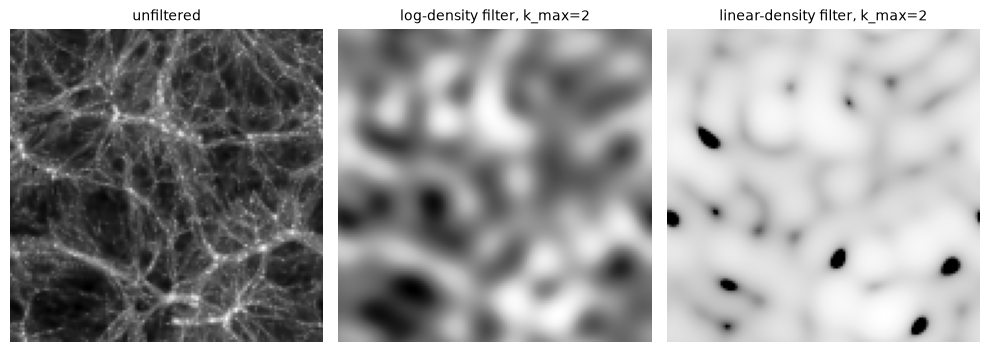

  epoch  1 | val 0.386 | 203s
  epoch  2 | val -0.963 | 199s
  epoch  3 | val -0.126 | 190s
  epoch  4 | val -1.118 | 195s
  epoch  5 | val -1.142 | 175s
  epoch  6 | val -1.003 | 94s
  epoch  7 | val -1.138 | 97s
  epoch  8 | val -1.252 | 96s
  epoch  9 | val -1.238 | 97s
  epoch 10 | val -1.251 | 98s
  test RMSE  Om 0.0666  s8 0.0774   (log-filter CNN: Om 0.0582  s8 0.0691)
CNN with linear-density k_max = 4 h/Mpc
  17.8159% of pixels clipped to stay positive (should be tiny)
  epoch  1 | val -0.788 | 125s
  epoch  2 | val -1.187 | 122s
  epoch  3 | val -1.154 | 123s
  epoch  4 | val -1.162 | 124s
  epoch  5 | val -1.333 | 118s
  epoch  6 | val -1.255 | 114s
  epoch  7 | val -1.379 | 114s
  epoch  8 | val -1.390 | 116s
  epoch  9 | val -1.444 | 112s
  epoch 10 | val -1.445 | 108s
  test RMSE  Om 0.0595  s8 0.0577   (log-filter CNN: Om 0.0471  s8 0.0551)
CNN with linear-density k_max = 8 h/Mpc
  18.3438% of pixels clipped to stay positive (should be tiny)
  epoch  1 | val -0.823 | 116s

In [47]:
import torch.nn.functional as tnf

kgrid256 = kmag.reshape(256, 256)      # |k| (h/Mpc) of every Fourier pixel of a 256x256 map, from the P(k) cell

def linear_lowpass_maps(kmax):
    """CNN inputs for ALL 15000 maps with small scales removed in LINEAR density, before the log:
    raw map -> Gaussian smoothing (R = 1/k_max) and a sharp cut at k_max -> log10 -> 128x128 -> standardize.
    Returns a float16 tensor (15000, 1, 128, 128) and the fraction of pixels clipped to keep the log finite."""
    R = 1.0 / kmax
    filt = np.exp(-0.5 * (kgrid256 * R) ** 2) * (kgrid256 <= kmax)
    out = np.empty((len(maps), 1, 128, 128), dtype=np.float16)
    n_clipped = 0
    for i in range(0, len(maps), CHUNK):
        c = np.asarray(maps[i:i+CHUNK], dtype=np.float64)
        sm = np.fft.ifft2(np.fft.fft2(c) * filt).real
        # Gaussian smoothing keeps the density positive, but the sharp cut can ring slightly below zero
        floor = 1e-3 * c.mean(axis=(1, 2), keepdims=True)
        n_clipped += int((sm < floor).sum())
        sm = np.maximum(sm, floor)
        logm = torch.from_numpy(np.log10(sm) - LOG_MEAN).float()[:, None]       # subtract ~9 before float16
        out[i:i+len(c)] = tnf.avg_pool2d(logm, 2).numpy().astype(np.float16)    # same 2x downsampling as before
    # standardize with TRAINING statistics (smoothing shrinks the fluctuations, so the old LOG_STD doesn't apply)
    sample = out[np.sort(rng.choice(train_idx, 1500, replace=False))].astype(np.float32)
    mu, sd = sample.mean(), sample.std()
    for i in range(0, len(out), 1000):
        out[i:i+1000] = ((out[i:i+1000].astype(np.float32) - mu) / sd).astype(np.float16)
    return torch.from_numpy(out), n_clipped / (len(maps) * 256 * 256)

# Each cutoff is another full CNN retraining (~20 min each on your CPU) plus a few minutes to filter all maps
LIN_CUTS = [2.0, 4.0, 8.0]
results["CNN (linear filter)"] = {K_NYQ: results["CNN"][K_NYQ]}   # with no cutoff it's the same network
t_tr, t_va, t_te = (torch.from_numpy(i) for i in (train_idx, val_idx, test_idx))
for kmax in LIN_CUTS:
    print(f"CNN with linear-density k_max = {kmax:g} h/Mpc")
    Xall, frac = linear_lowpass_maps(kmax)
    print(f"  {100*frac:.4f}% of pixels clipped to stay positive (should be tiny)")
    if kmax == LIN_CUTS[0]:   # compare the two filtering methods on the same test map
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
        panels = [(X_test[:1], "unfiltered"), (lowpass(X_test[:1], kmax), f"log-density filter, k_max={kmax:g}"),
                  (Xall[t_te[:1]], f"linear-density filter, k_max={kmax:g}")]
        for ax, (img, title) in zip(axes, panels):
            ax.imshow(img[0, 0].float().numpy(), cmap="Greys_r"); ax.set_title(title, fontsize=10); ax.axis("off")
        plt.tight_layout(); plt.show()
    net = train_cnn(Xall[t_tr], Xall[t_va], f"cosmo_cnn_linkmax{kmax:g}.pt")
    results["CNN (linear filter)"][kmax] = test_metrics(*predict_net(net, Xall[t_te]))
    print(f"  test RMSE  Om {results['CNN (linear filter)'][kmax][0][0]:.4f}  "
          f"s8 {results['CNN (linear filter)'][kmax][0][1]:.4f}   "
          f"(log-filter CNN: Om {results['CNN'][kmax][0][0]:.4f}  s8 {results['CNN'][kmax][0][1]:.4f})")
    del Xall

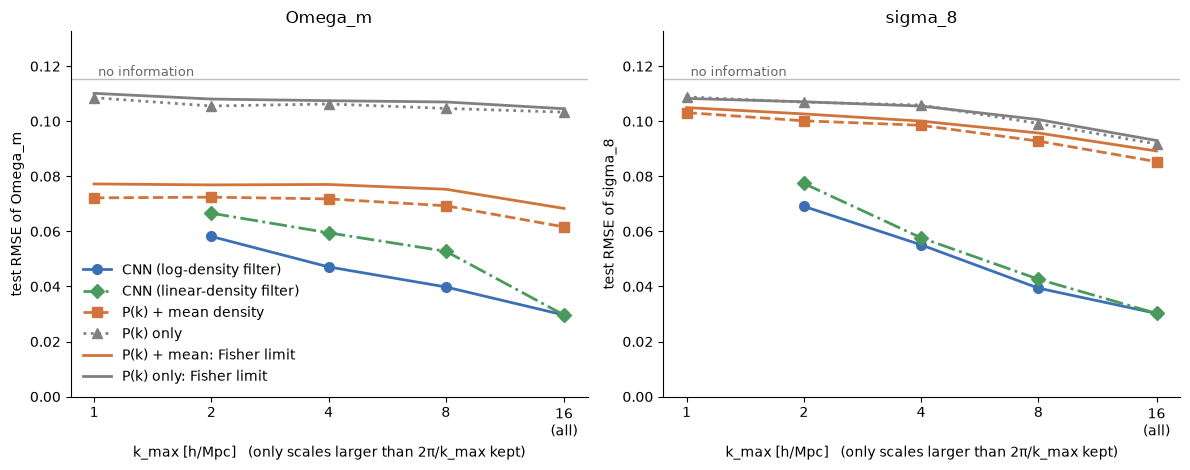

In [48]:
# Updated scale-cutoff plot, now including the linear-density-filtered CNN
plot_cutoffs("scale_comparison_linear.png")

## Fisher forecast: the best possible P(k) result

Instead of inferring the P(k) floor from several methods agreeing, compute it directly. Two ingredients:

1. **How much P(k) scatters at a fixed cosmology.** This is the covariance C of the features across the 405 CV maps, which all share Omega_m = 0.3 and sigma_8 = 0.8. Their scatter is pure cosmic variance.
2. **How fast P(k) changes with the parameters.** These are the derivatives ∂μ/∂θ: fit each feature as a smooth polynomial in (Omega_m, sigma_8) over the LH training simulations and take the slope at (0.3, 0.8).

The Fisher matrix F = (∂μ/∂θ)ᵀ C⁻¹ (∂μ/∂θ) then gives the best achievable single-map error, σ = √(F⁻¹)ᵢᵢ. If the parameters shift P(k) by much more than its random scatter, the parameters are easy to measure, and σ is small.

**The prior matters here.** P(k)'s σ is close to the width of the LH parameter range (prior σ = 0.4/√12 ≈ 0.115). The best estimator then pulls its guesses toward the middle of the range, which lowers its RMSE below the plain Fisher σ. So the code also reports:

- **expected RMSE (with prior):** √((F + P⁻¹)⁻¹), which approximates the best possible RMSE averaged over the prior. **Compare this to the LH test RMSE.**
- **optimal-estimator scatter at fiducial:** how much the best estimator's predictions spread across the CV maps. **Compare this to the regressors' CV scatter.**

**Reading the result:**
- If the regressors land at or near the "with prior" limit, the P(k) baseline is as good as P(k) gets, and the CNN comparison is fair.
- If they're well above it, they leave information unused.
- Being slightly *below* the limit is possible, because the forecast is an approximation (see the caveats).
- The CNN can beat this limit. The limit applies only to methods that use P(k); the CNN sees the whole map.
- The three "Fisher sigma" variants are robustness checks. If they roughly agree, the forecast doesn't hinge on how the covariance or derivatives were estimated.

**Caveats:**
- The forecast assumes the log P(k) values scatter as a Gaussian, with a covariance that doesn't depend on cosmology.
- It is computed at a single point (0.3, 0.8), while the test RMSE averages over the whole parameter range.
- The uniform prior is approximated by a Gaussian with the same width.
- The 15 maps of each CV simulation aren't fully independent, so the covariance is noisier than 405 samples would suggest.

In [49]:
# ---- Fisher forecast: the best error ANY method using these P(k) features could reach ----
fid = params_cv[0, :2]                       # fiducial cosmology of the CV set: (0.3, 0.8)
PRIOR_SIG = y_span / np.sqrt(12)             # standard deviation of the uniform LH prior on (Om, s8)

def pk_of_maps(m):
    """Same P(k) and mean-density features as the P(k) cell, for any stack of maps."""
    lp, lm = np.empty((len(m), W.shape[1])), np.empty(len(m))
    for i in range(0, len(m), CHUNK):
        c = np.asarray(m[i:i+CHUNK], dtype=np.float64)
        mean = c.mean(axis=(1, 2))
        delta = c / mean[:, None, None] - 1
        P = np.abs(np.fft.fft2(delta)) ** 2 * BOX**2 / 256**4
        lp[i:i+len(c)] = np.log10(P.reshape(len(c), -1) @ W)
        lm[i:i+len(c)] = np.log10(mean)
    return lp, lm

log_pk_cv, log_mean_cv = pk_of_maps(maps_cv)          # 405 maps: 27 sims x 15 maps, all at the fiducial cosmology

def feats(lp, lm, kmax, with_mean):
    F_ = lp[:, k_hi <= kmax * (1 + 1e-9)]
    return np.column_stack([F_, lm]) if with_mean else F_

def poly_design(x, deg):
    """All monomials Om^a * s8^b with a + b <= deg, in the centered parameters x = theta - fid."""
    cols, terms = [np.ones(len(x))], [(0, 0)]
    for d in range(1, deg + 1):
        for a in range(d, -1, -1):
            cols.append(x[:, 0] ** a * x[:, 1] ** (d - a)); terms.append((a, d - a))
    return np.column_stack(cols), terms

def derivs(F_lh, theta, deg=2):
    """Fit every feature as a polynomial in (Om, s8) over the LH training maps. Because the fit is centered
    on the fiducial, the linear coefficients are exactly d(feature)/d(theta) there. Returns (2, nfeat) and the fit."""
    A, terms = poly_design(theta - fid, deg)
    coef, *_ = np.linalg.lstsq(A, F_lh, rcond=None)
    return coef[[terms.index((1, 0)), terms.index((0, 1))]], A @ coef

def fisher_matrix(dmu, C, n):
    """F_ij = dmu_i^T C^-1 dmu_j. The Hartlap factor corrects the bias of inverting a covariance
    estimated from n samples."""
    C = np.atleast_2d(C)
    hartlap = (n - C.shape[0] - 2) / (n - 1)
    return dmu @ (hartlap * np.linalg.inv(C)) @ dmu.T

theta_tr = labels[train_idx]
near = np.all(np.abs(theta_tr - fid) < 0.05, axis=1)   # LH training maps close to the fiducial cosmology
Pinv = np.diag(1 / PRIOR_SIG ** 2)                     # Gaussian approximation of the uniform prior

def fisher_report(kmax, with_mean):
    F_lh = feats(log_pk[train_idx], log_mean[train_idx], kmax, with_mean)
    F_cv = feats(log_pk_cv, log_mean_cv, kmax, with_mean)
    d2, fitted = derivs(F_lh, theta_tr, deg=2)
    d3, _ = derivs(F_lh, theta_tr, deg=3)
    C_cv = np.cov(F_cv, rowvar=False)
    C_near = np.cov((F_lh - fitted)[near], rowvar=False)      # scatter around the mean, from LH sims near fiducial
    Fm = fisher_matrix(d2, C_cv, len(F_cv))
    post = np.linalg.inv(Fm + Pinv)                            # posterior covariance (linear-Gaussian approximation)
    sig = lambda M: np.sqrt(np.diag(M))
    return {
        "Fisher sigma (CV covariance)":           sig(np.linalg.inv(Fm)),
        "Fisher sigma (LH-near-fid covariance)":  sig(np.linalg.inv(fisher_matrix(d2, C_near, near.sum()))),
        "Fisher sigma (cubic derivative fit)":    sig(np.linalg.inv(fisher_matrix(d3, C_cv, len(F_cv)))),
        "expected RMSE (with prior)":             sig(post),
        "optimal-estimator scatter at fiducial":  sig(post @ Fm @ post),
    }

print(f"{len(log_pk_cv)} CV maps, {near.sum()} LH training maps within ±0.05 of the fiducial")

405 CV maps, 825 LH training maps within ±0.05 of the fiducial


In [50]:
# Compare the Fisher limit with what the regressors actually achieve, using all scales
for with_mean, flabel in [(False, "P(k) only"), (True, "P(k) + mean density")]:
    rep = fisher_report(K_NYQ, with_mean)
    print(f"===== {flabel} (all scales) =====")
    print("Fisher forecast, single map at the fiducial cosmology:")
    for name, s in rep.items():
        print(f"  {name:38s} Om {s[0]:.4f}   s8 {s[1]:.4f}")

    Ftr, Fva, Fte = (feats(log_pk[i], log_mean[i], K_NYQ, with_mean) for i in (train_idx, val_idx, test_idx))
    Fcv = feats(log_pk_cv, log_mean_cv, K_NYQ, with_mean)
    mlp = train_mlp(Ftr, Fva)
    methods = {"linear ridge":    lambda Fx: ridge_predict(Ftr, Fva, Fx),
               "quadratic ridge": lambda Fx: ridge_predict(Ftr, Fva, Fx, quadratic=True),
               "MLP (150 ep)":    lambda Fx: mlp(Fx)[0]}
    print("Regressors:                  LH test RMSE      |   CV scatter      |   CV bias")
    for mname, fn in methods.items():
        rmse_lh = test_rmse(fn(Fte))
        p_cv = denorm_y(fn(Fcv))
        scat, bias = p_cv.std(0), p_cv.mean(0) - fid
        print(f"  {mname:16s}  Om {rmse_lh[0]:.4f} s8 {rmse_lh[1]:.4f} | Om {scat[0]:.4f} s8 {scat[1]:.4f} "
              f"| Om {bias[0]:+.4f} s8 {bias[1]:+.4f}")
    print()
print("Compare: LH test RMSE  <->  'expected RMSE (with prior)'")
print("         CV scatter    <->  'optimal-estimator scatter at fiducial'")

===== P(k) only (all scales) =====
Fisher forecast, single map at the fiducial cosmology:
  Fisher sigma (CV covariance)           Om 0.5886   s8 0.4125
  Fisher sigma (LH-near-fid covariance)  Om 0.6147   s8 0.4195
  Fisher sigma (cubic derivative fit)    Om 0.5015   s8 0.2674
  expected RMSE (with prior)             Om 0.1046   s8 0.0930
  optimal-estimator scatter at fiducial  Om 0.0359   s8 0.0487
Regressors:                  LH test RMSE      |   CV scatter      |   CV bias
  linear ridge      Om 0.1058 s8 0.0957 | Om 0.0343 s8 0.0508 | Om +0.0115 s8 +0.0114
  quadratic ridge   Om 0.1019 s8 0.0932 | Om 0.0323 s8 0.0502 | Om +0.0187 s8 +0.0145
  MLP (150 ep)      Om 0.1033 s8 0.0918 | Om 0.0340 s8 0.0527 | Om +0.0062 s8 +0.0134

===== P(k) + mean density (all scales) =====
Fisher forecast, single map at the fiducial cosmology:
  Fisher sigma (CV covariance)           Om 0.0868   s8 0.1426
  Fisher sigma (LH-near-fid covariance)  Om 0.0848   s8 0.1347
  Fisher sigma (cubic derivativ

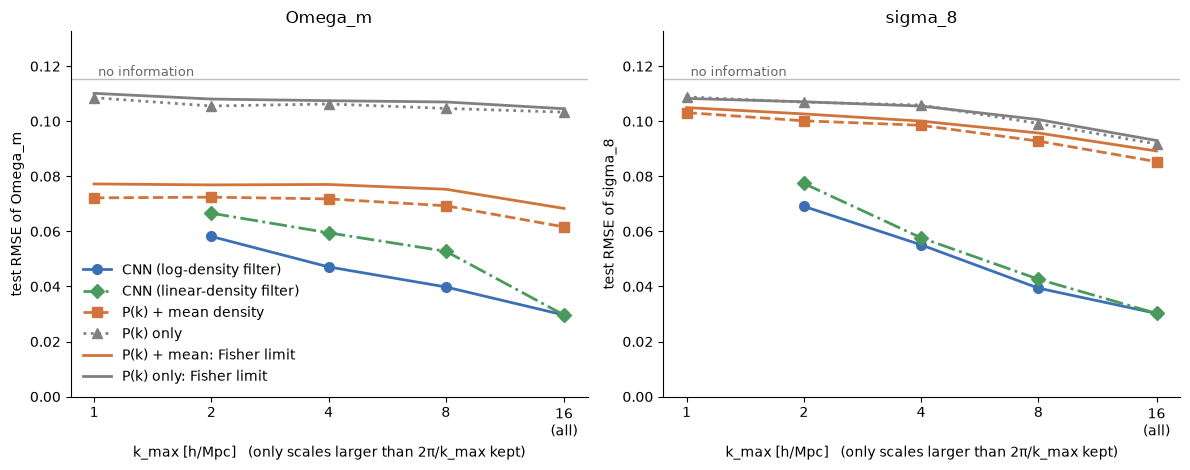

In [51]:
# Add the Fisher limit (expected RMSE including the prior) to the scale-cutoff plot
fisher_curves = {"P(k) + mean density": {}, "P(k) only": {}}
for flabel, with_mean in [("P(k) + mean density", True), ("P(k) only", False)]:
    for kmax in CUTOFFS:
        fisher_curves[flabel][kmax] = (fisher_report(kmax, with_mean)["expected RMSE (with prior)"], None)
results["Fisher: P(k) + mean density"] = fisher_curves["P(k) + mean density"]
results["Fisher: P(k) only"] = fisher_curves["P(k) only"]
STYLES["Fisher: P(k) + mean density"] = dict(label="P(k) + mean: Fisher limit", color="#d0743c", marker="", ls="-")
STYLES["Fisher: P(k) only"] = dict(label="P(k) only: Fisher limit", color="0.5", marker="", ls="-")
plot_cutoffs("scale_comparison_fisher.png")